<a href="https://colab.research.google.com/github/ak80333/esp_test/blob/main/notebooks/run_Cellpose-SAM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Cellpose-SAM: superhuman generalization for cellular segmentation

Marius Pachitariu, Michael Rariden, Carsen Stringer

[paper](https://www.biorxiv.org/content/10.1101/2025.04.28.651001v1) | [code](https://github.com/MouseLand/cellpose)

This notebook shows how to process your own 2D or 3D images, saved on Google Drive.

This notebook is adapted from the notebook by Pradeep Rajasekhar, inspired by the [ZeroCostDL4Mic notebook series](https://github.com/HenriquesLab/ZeroCostDL4Mic/wiki).

### Make sure you have GPU access enabled by going to Runtime -> Change Runtime Type -> Hardware accelerator and selecting GPU

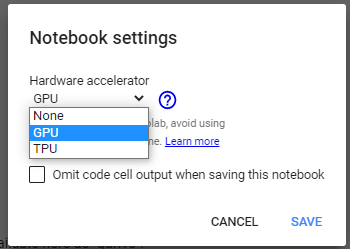

### Mount your google drive

Run this cell to connect your Google Drive to colab:
* Click on the URL.
* Sign in your Google Account.

You will either have to:
* copy the authorisation code and enter it into box below OR
* in the new google colab, you can just click "Allow" and it should connect.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive



Then click on "Folder" icon on the Left, press the refresh button. Your Google Drive folder should now be available here as "gdrive".


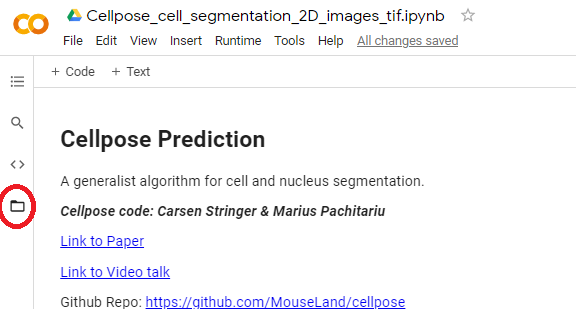

Click on the triangle icon and it will allow you to access whole drive. Navigate to the folder containing your images. Once you are there, click on the three dots on the right of the folder and select "Copy Path"

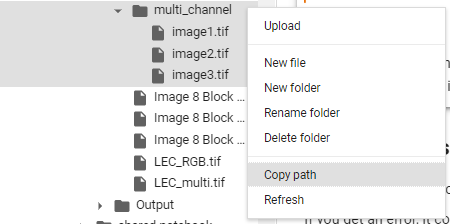

Copy and paste this path in the **dir** string below

### Install Cellpose-SAM


In [2]:
!uv pip install git+https://www.github.com/mouseland/cellpose.git
!uv pip install git+https://github.com/facebookresearch/dinov3.git

Using Python 3.13.16 environment at: /usr
Resolved 43 packages in 9.62s
Prepared 6 packages in 415ms
Installed 6 packages in 3ms
 + cellpose==4.2.1.1 (from git+https://www.github.com/mouseland/cellpose.git@a54cb48849b7e225a81e8e43dcb042d42427f543)
 + fastremap==1.21.0
 + fill-voids==2.1.2
 + imagecodecs==2026.10.10
 + roifile==2026.11.6
 + segment-anything==1.0
Using Python 3.13.16 environment at: /usr
Resolved 48 packages in 3.13s
Prepared 5 packages in 441ms
Installed 5 packages in 7ms
 + dinov3==0.0.1 (from git+https://github.com/facebookresearch/dinov3.git@6876159a11b4df116f30f667f8c9888617df0751)
 + ftfy==6.3.1
 + lightning-utilities==0.15.3
 + submitit==1.5.4
 + torchmetrics==1.9.0


Check GPU and instantiate model - will download weights.

In [3]:
import numpy as np
from cellpose import models, core, io, plot
from pathlib import Path
from tqdm import trange
import matplotlib.pyplot as plt
from natsort import natsorted

io.logger_setup() # run this to get printing of progress

#Check if colab notebook instance has GPU access
if core.use_gpu()==False:
  raise ImportError("No GPU access, change your runtime")

model = models.CellposeModel(gpu=True)

### You can also use other pretrained models, like the DINO models
# model = models.CellposeModel(gpu=True, pretrained_model="cpdino")
# model = models.CellposeModel(gpu=True, pretrained_model="cpdino-vitb")

creating new log file
[GUI INFO] : WRITING LOG OUTPUT TO /root/.cellpose/run.log

cellpose version: 	4.2.1.1 
platform:       	linux 
python version: 	3.13.16 
torch version:  	2.14.1+cu130
2026-11-10 04:07:50,310 [io INFO] WRITING LOG OUTPUT TO /root/.cellpose/run.log
2026-11-10 04:07:50,310 [io INFO] 
cellpose version: 	4.2.1.1 
platform:       	linux 
python version: 	3.13.16 
torch version:  	2.14.1+cu130
2026-11-10 04:07:50,759 [core INFO] ** TORCH CUDA version installed and working. **
2026-11-10 04:07:50,760 [core INFO] ** TORCH CUDA version installed and working. **
2026-11-10 04:07:50,761 [core INFO] >>>> using GPU (CUDA)
2026-11-10 04:07:50,762 [models INFO] Downloading: "https://huggingface.co/mouseland/cellpose-sam/resolve/main/cpsam_v2" to /root/.cellpose/models/cpsam_v2



100%|██████████| 1.15G/1.15G [00:08<00:00, 139MB/s]


2026-11-10 04:08:02,915 [models INFO] >>>> loading model /root/.cellpose/models/cpsam_v2


Input directory with your images:

In [4]:
# *** change to your google drive folder path ***
dir = "/content/drive/MyDrive/cellpose-sam/"
dir = Path(dir)
if not dir.exists():
  raise FileNotFoundError("directory does not exist")

# *** change to your image extension ***
image_ext = ".jpg"

# list all files
files = natsorted([f for f in dir.glob("*"+image_ext) if "_masks" not in f.name and "_flows" not in f.name])

if(len(files)==0):
  raise FileNotFoundError("no image files found, did you specify the correct folder and extension?")
else:
  print(f"{len(files)} images in folder:")

for f in files:
  print(f.name)

5 images in folder:
BR3_Final EB 10배 희석_0004.jpg
BR3_Final EB 10배 희석_0006.jpg
BR3_Final EB 10배 희석_0008.jpg
BR3_Final EB 10배 희석_0010.jpg
BR3_Final EB 10배 희석_0012.jpg


## Run Cellpose-SAM on one image in folder

Here are some of the parameters you can change:

* ***flow_threshold*** is  the  maximum  allowed  error  of  the  flows  for  each  mask.   The  default  is 0.4.
    *  **Increase** this threshold if cellpose is not returning as many masks as you’d expect (or turn off completely with 0.0)
    *   **Decrease** this threshold if cellpose is returning too many ill-shaped masks.

* ***cellprob_threshold*** determines proability that a detected object is a cell.   The  default  is 0.0.
    *   **Decrease** this threshold if cellpose is not returning as many masks as you’d expect or if masks are too small
    *   **Increase** this threshold if cellpose is returning too many masks esp from dull/dim areas.

* ***tile_norm_blocksize*** determines the size of blocks used for normalizing the image. The default is 0, which means the entire image is normalized together.
  You may want to change this to 100-200 pixels if you have very inhomogeneous brightness across your image.



In [5]:
img = io.imread(files[0])

print(f'your image has shape: {img.shape}. Assuming channel dimension is last with {img.shape[-1]} channels')

your image has shape: (2160, 3840, 3). Assuming channel dimension is last with 3 channels


### Channel Selection:

- Use the dropdowns below to select the _zero-indexed_ channels of your image to segment. The order does not matter. Remember to rerun the cell after you edit the dropdowns.

- If you have a histological image taken in brightfield, you don't need to adjust the channels.

- If you have a fluroescent image with multiple stains, you should choose one channel with a cytoplasm/membrane stain, one channel with a nuclear stain, and set the third channel to `None`. Choosing multiple channels may produce segmentaiton of all the structures in the image. If you have retrained the model on your data with a third stain (described below), you can run segmentation with all channels.

In [6]:
first_channel = '0' # @param ['None', 0, 1, 2, 3, 4, 5]
second_channel = '1' # @param ['None', 0, 1, 2, 3, 4, 5]
third_channel = '2' # @param ['None', 0, 1, 2, 3, 4, 5]

/usr/local/lib/python3.13/dist-packages/cellpose/dynamics.py:541: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:848.)
  coo = torch.sparse_coo_tensor(pt, torch.ones(pt.shape[1], device=pt.device, dtype=torch.int),


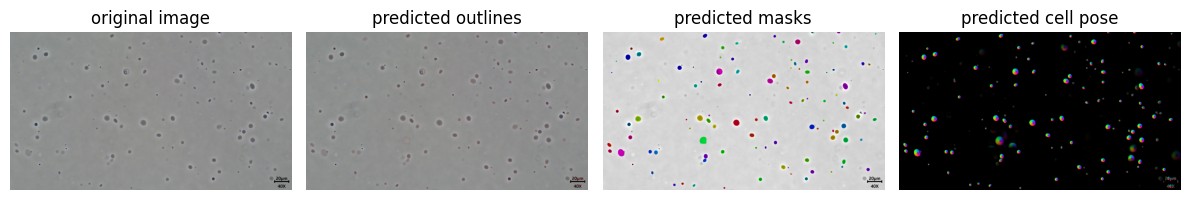

In [7]:
selected_channels = []
for i, c in enumerate([first_channel, second_channel, third_channel]):
  if c == 'None':
    continue
  if int(c) > img.shape[-1]:
    assert False, 'invalid channel index, must have index greater or equal to the number of channels'
  if c != 'None':
    selected_channels.append(int(c))



img_selected_channels = np.zeros_like(img)
img_selected_channels[:, :, :len(selected_channels)] = img[:, :, selected_channels]


flow_threshold = 0.4
cellprob_threshold = 0.0
tile_norm_blocksize = 0

masks, flows, styles = model.eval(img_selected_channels, batch_size=32, flow_threshold=flow_threshold, cellprob_threshold=cellprob_threshold,
                                  normalize={"tile_norm_blocksize": tile_norm_blocksize})

fig = plt.figure(figsize=(12,5))
plot.show_segmentation(fig, img_selected_channels, masks, flows[0])
plt.tight_layout()
plt.show()


## Run Cellpose-SAM on folder of images

if you have many large images, you may want to run them as a loop over images



In [8]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from cellpose import io, plot
from tqdm.auto import trange

flow_threshold = 0.0
cellprob_threshold = -3.0
tile_norm_blocksize = 0
batch_size = 4  # GPU 메모리 부담을 줄이기 위해 32 → 4

# 오른쪽 아래 제외 영역의 시작 위치
# 오른쪽 15%와 아래쪽 10%가 겹치는 사각형만 제외
exclude_x_ratio = 0.85
exclude_y_ratio = 0.90

output_dir = Path(dir) / "results8_no_scalebar"
output_dir.mkdir(parents=True, exist_ok=True)

for i in trange(len(files)):
    f = Path(files[i])
    img = io.imread(f)

    # 2D 회색조 또는 H×W×C 형태의 이미지 기준
    if img.ndim not in (2, 3):
        raise ValueError(f"{f.name}: 지원하지 않는 이미지 형태 {img.shape}")

    h, w = img.shape[:2]
    x0 = int(w * exclude_x_ratio)
    y0 = int(h * exclude_y_ratio)

    # 1. 분석용 이미지에서 스케일바 영역을 주변 배경색으로 덮기
    # 원본 img는 그대로 보관
    img_for_model = img.copy()

    # 제외 영역 바로 위쪽 띠에서 배경 밝기 추정
    reference_height = max(1, int(h * 0.05))
    reference = img[max(0, y0 - reference_height):y0, x0:]

    # 회색조는 밝기 하나, 컬러는 채널별 배경 밝기 계산
    background = np.median(reference, axis=(0, 1))
    img_for_model[y0:, x0:] = background

    masks, flows, styles = model.eval(
        img_for_model,
        batch_size=batch_size,
        flow_threshold=flow_threshold,
        cellprob_threshold=cellprob_threshold,
        min_size=5,
        normalize={"tile_norm_blocksize": tile_norm_blocksize}
    )

    # 2. 제외 영역 또는 그 경계에 닿는 개체는 전체 삭제
    # 일부만 남겨서 직경이 작게 계산되는 것을 방지
    excluded_ids = np.unique(
        masks[max(0, y0 - 1):, max(0, x0 - 1):]
    )
    excluded_ids = excluded_ids[excluded_ids > 0]

    if excluded_ids.size > 0:
        masks[np.isin(masks, excluded_ids)] = 0

    masks[y0:, x0:] = 0

    # 남은 개체 번호를 1, 2, 3...으로 다시 정리
    remaining_ids = np.unique(masks)
    remaining_ids = remaining_ids[remaining_ids > 0]

    lookup = np.zeros(int(masks.max()) + 1, dtype=masks.dtype)
    lookup[remaining_ids] = np.arange(
        1, len(remaining_ids) + 1, dtype=masks.dtype
    )
    masks = lookup[masks]

    # 3. 분석용 마스크 TIFF 저장
    io.imsave(
        output_dir / f"{f.stem}_masks.tif",
        masks
    )

    # flow 시각화에서도 제외 영역을 검은색으로 표시
    flow_rgb = flows[0].copy()
    flow_rgb[y0:, x0:] = 0

    # 4. 원본 및 결과 이미지 저장
    fig = plt.figure(figsize=(16, 5))

    try:
        # 배경은 원본을 사용하므로 스케일바 자체는 보존됨
        # 검출 마스크와 외곽선에서는 해당 영역이 제외됨
        plot.show_segmentation(fig, img, masks, flow_rgb)

        panel_names = [
            "original",
            "outlines",
            "predicted_masks",
            "cellpose"
        ]

        for ax, name in zip(fig.axes, panel_names):
            panel_image = np.asarray(ax.images[0].get_array())

            plt.imsave(
                output_dir / f"{f.stem}_{name}.png",
                panel_image
            )

    finally:
        plt.close(fig)

print(f"저장 완료: {output_dir}")

  0%|          | 0/5 [00:00<?, ?it/s]

KeyboardInterrupt: 

if you have small images, you may want to load all of them first and then run, so that they can be batched together on the GPU

In [ ]:
%run /content/cellpose_diameter_analysis.py

RESULT_DIR = Path(dir) / "results8_no_scalebar"

# 자동 검출이 잘못된 이미지가 있으면 좌표를 직접 지정
# 파일명은 "_masks.tif"를 뺀 이름
# 좌표는 원본 이미지 기준: (첫 픽셀 x, 마지막 픽셀 x, 중앙 y)
MANUAL_BARS = {
    # "이미지파일명": (왼쪽_x, 오른쪽_x, 중앙_y),
}

calibration = review_scales(
    RESULT_DIR,
    scale_um=100.0,          # 가로 스케일바 전체 길이 = 100 µm
    manual_bars=MANUAL_BARS,
    x_ratio=0.85,            # 오른쪽 아래 검색 영역
    y_ratio=0.90,
)

In [ ]:
objects, summary = analyze_diameters(
    RESULT_DIR,
    calibration,
    n_bins=80,           # 분포를 나눌 구간 수
    exclude_edges=True, # 이미지 가장자리에 걸려 잘린 개체는 통계에서 제외
)

In [ ]:
%run /content/cellpose_multisizer_compare.py

from pathlib import Path

# 업로드한 원본 파일명
M4_FILE = "/content/s260821_day2_Final EB_BR3.ap100_2026-08-24_17-56_26.#m4"

# 이미지별 분석 + 모든 시야를 합친 그래프
objects, summary = analyze_diameters(
    RESULT_DIR,
    calibration,
    n_bins=80,
    exclude_edges=True,
)

# 이미지 한 장 = 0.00005 mL 가정
n_images = calibration["image"].nunique()
total_volume_ml = n_images * 0.00005

# 합산 이미지 결과와 #m4 원본 비교
comparison = compare_with_multisizer(
    objects=objects,
    multisizer_files=[M4_FILE],
    output_dir=Path(RESULT_DIR) / "diameter_analysis",
    n_bins=80,
    image_total_effective_volume_ml=total_volume_ml,
    image_dilution_factor=1.0,
    image_volume_note=(
        f"Assumed at 20x: {n_images} images x 0.00005 mL/image; "
        f"total {total_volume_ml:g} mL"
    ),
)

to save your masks for ImageJ, run the following code:

In [ ]:
for i in trange(len(files)):
    f = files[i]
    io.imsave(dir / (f.name + "_masks" + masks_ext), masks[i])
    io.save_rois(masks[i], f)

100%|██████████| 5/5 [00:11<00:00,  2.39s/it]
